# 85 A least-cost peak-reduction stack: flexible loads first, then batteries

Notebook 80 puts a battery in every home. This notebook asks the business question behind it: **what is the cheapest
way to take a given number of megawatts off the grid's peak, and which customers should get what?** It puts the
clusters (notebook 75) and appliance flags (notebook 60) to work:

1. **The peak**: when the grid's 100 highest hours happen and which clusters drive them.
2. **Flexible loads** found by the appliance flags, which can be shifted or trimmed for a small fraction of a battery's
   cost: central AC (smart thermostat events), pool pumps, electric water heaters and Level 2 EV charging.
3. **Batteries**, using each home's simulated result from notebook 80, counted only for what they add on top of the
   flexible loads in the same home.
4. **A supply curve**: every home-and-measure option ranked by dollars per kW of peak reduction, and the cost of
   reaching a target with the full stack against batteries alone.
5. **Which homes should get batteries**: ranked by cluster.
6. **Who pays**: battery payback from bill savings, and the capacity value each option needs to break even.

**Peak reduction** throughout means the cut in a home's average load over the grid's 100 highest hours, the measure
notebook 80 uses (`grid_peak_kw_reduction`).

**The costs and savings rates are placeholders**, like the tariff in notebook 80: they're set in one cell (section 2)
and should be replaced with Avangrid's programme costs and measured savings. The appliance flags are rule-based and
unvalidated (notebook 95 shows the water-heater flag is partly confused with hot tubs).

Outputs: DuckDB table `peak_reduction_stack` (one row per customer), `onedrive-export/Data/eda/peak_reduction_stack.csv`,
`peak_reduction_supply_curve.png`, `peak_reduction_cost_to_target.png`, `peak_hours_by_time_of_day.png`.

Run after notebooks 75 and 80. It takes about a minute.

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import avangrid  # noqa: F401
from avangrid import battery as bt, cache, config, db, grids

PLOT_DIR = config.EDA_DIR

## 1. The peak: when it happens and who drives it

The system load is the sum of all customers in the analysis (missing hours filled as in notebook 80). The chart
shows the time of day of the 100 highest hours, with the placeholder tariff's on-peak window (4–9 pm on weekdays)
shaded: a battery dispatched against that tariff discharges only in those hours.

System peak 78.0 MW; the 100 highest hours range from 57.1 MW up, on 18 days (June 16, July 71, August 13 hours).
Average home in those hours: 1.91 kW. Total: 63.6 MW.
Share of the 100 hours inside the tariff's on-peak window (4-9 pm weekdays): 46%; on a weekend: 20%; before 4 pm: 30%; after 9 pm: 8%.


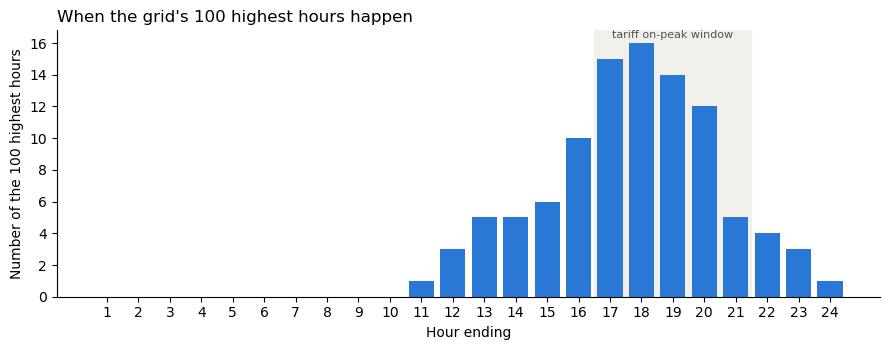

In [2]:
PEAK_HOURS = 100
hd = grids.load_hourly(verbose=False)
n = hd.shape[0]
L = bt.fill_missing(hd.kwh, hd.dates)                       # customers x days x 24
flat = L.reshape(n, -1)
system = flat.sum(0, dtype=np.float64)
top = np.argsort(-system)[:PEAK_HOURS]
top_day, top_hour = np.divmod(top, 24)
peak_kw = flat[:, top].mean(1, dtype=np.float64)            # each home's average load in the 100 highest hours
w = np.bincount(top_hour, minlength=24) / PEAK_HOURS         # share of the peak hours at each hour of the day
on_peak = bt.Tariff().hourly(hd.dates)['on_peak']
ON_SHARE = float(on_peak[top].mean())

months = hd.dates.dt.month().to_numpy()[top_day]
print(f'System peak {system.max() / 1000:.1f} MW; the 100 highest hours range from {system[top].min() / 1000:.1f} MW up, '
      f'on {len(set(top_day))} days (June {np.sum(months == 6)}, July {np.sum(months == 7)}, August {np.sum(months == 8)} hours).')
print(f'Average home in those hours: {peak_kw.mean():.2f} kW. Total: {peak_kw.sum() / 1000:.1f} MW.')
print(f"Share of the 100 hours inside the tariff's on-peak window (4-9 pm weekdays): {ON_SHARE:.0%}; "
      f'on a weekend: {hd.weekend[top_day].mean():.0%}; before 4 pm: {w[:16].sum():.0%}; after 9 pm: {w[21:].sum():.0%}.')

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axvspan(16.5, 21.5, color='#f1f0ec', zorder=0)
ax.text(19, w.max() * 100 * 1.02, 'tariff on-peak window', ha='center', fontsize=8, color='#52514e')
ax.bar(np.arange(1, 25), w * 100, color='#2a78d6', width=0.8)
ax.set_xticks(range(1, 25))
ax.set_xlabel('Hour ending')
ax.set_ylabel('Number of the 100 highest hours')
ax.set_title("When the grid's 100 highest hours happen", loc='left')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(PLOT_DIR / 'peak_hours_by_time_of_day.png', dpi=150)
plt.show()

### Which clusters drive the peak

Notebook 75's clusters (engineered features plus appliance flags), with each cluster's share of customers and of
load in the 100 highest hours.

In [3]:
cust = hd.customers.select('CUSTOMER_NUMBER')


def attach(query):
    return cust.join(db.sql(query), on='CUSTOMER_NUMBER', how='left', maintain_order='left')


inv = attach('SELECT * FROM appliance_inventory')
bat = attach('SELECT CUSTOMER_NUMBER, bill_savings, bill_before, grid_peak_kw_reduction, charge_window FROM battery_simulation')
mixed = attach('SELECT CUSTOMER_NUMBER, mixed_cluster, mixed_description FROM customer_segments_mixed')
seg70 = attach('SELECT CUSTOMER_NUMBER, segment FROM customer_segments')['segment'].to_numpy()
evidence = attach("SELECT * FROM read_parquet('" + str(config.RESULTS_DIR / 'appliance_features.parquet') + "')")
cluster = np.array([f"{c}: {', '.join(d.split(', ')[:2])}" for c, d in
                    zip(mixed['mixed_cluster'], mixed['mixed_description'])])

base = pl.DataFrame({'cluster': cluster, 'peak_kw': peak_kw})
who = (base.group_by('cluster').agg(pl.len().alias('customers'), pl.col('peak_kw').sum().alias('peak_kw_total'),
                                    pl.col('peak_kw').mean().alias('avg_peak_kw'))
       .with_columns((pl.col('customers') / n).alias('share_customers'),
                     (pl.col('peak_kw_total') / peak_kw.sum()).alias('share_of_peak'))
       .with_columns((pl.col('share_of_peak') / pl.col('share_customers')).alias('peak_intensity'))
       .sort('cluster').select('cluster', 'customers', 'share_customers', 'share_of_peak', 'peak_intensity', 'avg_peak_kw'))
with pl.Config(tbl_hide_dataframe_shape=True, float_precision=2, fmt_str_lengths=70, tbl_width_chars=160):
    print(who)

┌────────────────────────────────────────────────────────────────┬───────────┬─────────────────┬───────────────┬────────────────┬─────────────┐
│ cluster                                                        ┆ customers ┆ share_customers ┆ share_of_peak ┆ peak_intensity ┆ avg_peak_kw │
│ ---                                                            ┆ ---       ┆ ---             ┆ ---           ┆ ---            ┆ ---         │
│ str                                                            ┆ u32       ┆ f64             ┆ f64           ┆ f64            ┆ f64         │
╞════════════════════════════════════════════════════════════════╪═══════════╪═════════════════╪═══════════════╪════════════════╪═════════════╡
│ 0: room AC 100%                                                ┆ 11189     ┆ 0.34            ┆ 0.26          ┆ 0.79           ┆ 1.50        │
│ 1: central AC 99%, heavy cooling                               ┆ 10250     ┆ 0.31            ┆ 0.47          ┆ 1.51           ┆ 2.89  

## 2. Assumptions (placeholders)

Everything that isn't measured from the meter data is set here. Replace these with Avangrid's programme costs and
measured event savings.

| Assumption | Value | Basis |
|---|---|---|
| Smart-thermostat event | sheds 30% of a central-AC home's cooling load in peak hours | a 2–4 °F setback; planning assumption |
| Pool pump | moved entirely out of the peak hours | pumps run 8–10 hours from 8–9 am, as in notebook 60's simulated pumps |
| Water heater control | defers all evening heating until after the peak | evening draws as detected by the water-heater evidence |
| Managed EV charging | removes 0.8 kW per Level 2 home in peak hours | planning assumption for unmanaged evening charging; not measured |
| Cost per enrolled home | thermostat $150, pool $200, water heater $300, EV $200 | device or incentive plus set-up; one-off |
| Battery | $18,000 installed for the 20 kWh battery of notebook 80 | placeholder |
| Lifetimes | 10 years for flexible-load measures, 15 for batteries | used only to annualize costs (cost ÷ years, no financing) |

Every flagged home is assumed to enrol (the technical potential); section 4 also shows a 25% enrolment case.

In [4]:
THERMOSTAT_CURTAIL = 0.30      # share of cooling load shed during an event
EV_PEAK_KW = 0.8               # Level 2 charging load per EV home in peak hours, before management
WH_MAX_DRAW_KWH = 4.5          # cap on a water heater's evening draw (one hour of a 4.5 kW element)
COST = {'Smart thermostat (central AC)': 150, 'Pool pump schedule': 200, 'Water heater control': 300,
        'Managed EV charging': 200, 'Battery': 18_000}
LIFE_YEARS = {'Smart thermostat (central AC)': 10, 'Pool pump schedule': 10, 'Water heater control': 10,
              'Managed EV charging': 10, 'Battery': 15}
ENROLMENT_CASE = 0.25
COLORS = {'Smart thermostat (central AC)': '#0072B2', 'Pool pump schedule': '#009E73',
          'Water heater control': '#E69F00', 'Managed EV charging': '#CC79A7', 'Battery': '#52514e'}

## 3. Flexible loads: how much each flagged home could take off the peak

- **Central AC.** Each home's **cooling load at peak** is measured from its own data: its average load in the 100
  highest hours, minus its average load at the same hours of the day on mild days (daily average 60–68 °F). A
  thermostat event sheds the assumed share of that. Only homes flagged "central likely" count; room units aren't
  controlled by a thermostat.
- **Pool pump.** The pump's size is the home's daytime floor jump (`pool_daytime_floor_jump_kw`, notebook 60). It is
  multiplied by the chance the pump is running in a peak hour, given the assumed schedule.
- **Water heater.** Expected evening load = the share of days with an evening spike × the typical spike size, spread
  over the 6-hour evening window (hour ending 17–22), for the peak hours that fall in that window.
- **EV Level 2.** The assumed kW for every home flagged "Level 2 likely".

A home's flexible loads are added together and capped at its measured load in the peak hours.

In [5]:
mild = (hd.temp >= 60) & (hd.temp <= 68)
baseline = np.zeros(n)
for s0 in range(0, n, 4000):
    baseline[s0:s0 + 4000] = L[s0:s0 + 4000][:, mild, :].mean(1, dtype=np.float64) @ w
cooling_at_peak = np.maximum(peak_kw - baseline, 0)
central = (inv['ac_type'] == 'central likely').fill_null(False).to_numpy()

p_on = np.array([np.mean([((h - first) % 24) < length for first in (8, 9) for length in (8, 9, 10)]) for h in range(24)])
POOL_COINCIDENCE = float(p_on @ w)
pump_kw = np.clip(np.nan_to_num(inv['pool_daytime_floor_jump_kw'].to_numpy()), 0, 2.5)

wh_flag = inv['water_heater_flag'].fill_null(False).to_numpy()
draw = evidence['wh_morning_kwh'].to_numpy()
draw = np.clip(np.where(np.isfinite(draw), draw, np.nanmedian(draw[wh_flag])), 0, WH_MAX_DRAW_KWH)
evening_share = np.nan_to_num(evidence['wh_evening_share'].to_numpy())
WH_WINDOW = float(w[16:22].sum())

flex = {
    'Smart thermostat (central AC)': np.where(central, THERMOSTAT_CURTAIL * cooling_at_peak, 0.0),
    'Pool pump schedule': np.where(inv['pool_flag'].fill_null(False).to_numpy(), pump_kw * POOL_COINCIDENCE, 0.0),
    'Water heater control': np.where(wh_flag, evening_share * draw / 6 * WH_WINDOW, 0.0),
    'Managed EV charging': np.where((inv['ev_charging_type'] == 'Level 2 likely').fill_null(False).to_numpy(), EV_PEAK_KW, 0.0),
}
total = np.sum(list(flex.values()), axis=0)
scale = np.where(total > peak_kw, peak_kw / np.maximum(total, 1e-9), 1.0)      # cap at the home's peak-hour load
flex = {k: v * scale for k, v in flex.items()}
flex_kw = np.sum(list(flex.values()), axis=0)

print(f'Chance a pool pump is running in a peak hour: {POOL_COINCIDENCE:.0%}; '
      f'share of peak hours in the evening water-heating window: {WH_WINDOW:.0%}')
print(f'Median cooling load at peak, central-AC homes: {np.median(cooling_at_peak[central]):.2f} kW '
      f'({np.median(cooling_at_peak[central] / peak_kw[central]):.0%} of their peak-hour load)')
measures = pl.DataFrame([{'measure': k, 'homes': int((v > 0.01).sum()), 'kw_per_home': float(v[v > 0.01].mean()),
                          'total_mw': float(v.sum() / 1000), 'cost_musd': COST[k] * int((v > 0.01).sum()) / 1e6,
                          'cost_per_kw': COST[k] * int((v > 0.01).sum()) / v.sum(),
                          'cost_per_kw_year': COST[k] / LIFE_YEARS[k] * int((v > 0.01).sum()) / v.sum()}
                         for k, v in flex.items()])
with pl.Config(tbl_hide_dataframe_shape=True, float_precision=2, fmt_str_lengths=40, tbl_width_chars=160):
    print(measures)
print(f'All flexible loads together: {flex_kw.sum() / 1000:.1f} MW ({flex_kw.sum() / peak_kw.sum():.0%} of the peak-hour load), '
      f'{int((flex_kw > 0.01).sum()):,} homes, ${measures["cost_musd"].sum():.1f}M')

Chance a pool pump is running in a peak hour: 53%; share of peak hours in the evening water-heating window: 66%
Median cooling load at peak, central-AC homes: 1.59 kW (60% of their peak-hour load)
┌───────────────────────────────┬───────┬─────────────┬──────────┬───────────┬─────────────┬──────────────────┐
│ measure                       ┆ homes ┆ kw_per_home ┆ total_mw ┆ cost_musd ┆ cost_per_kw ┆ cost_per_kw_year │
│ ---                           ┆ ---   ┆ ---         ┆ ---      ┆ ---       ┆ ---         ┆ ---              │
│ str                           ┆ i64   ┆ f64         ┆ f64      ┆ f64       ┆ f64         ┆ f64              │
╞═══════════════════════════════╪═══════╪═════════════╪══════════╪═══════════╪═════════════╪══════════════════╡
│ Smart thermostat (central AC) ┆ 12028 ┆ 0.51        ┆ 6.19     ┆ 1.80      ┆ 291.36      ┆ 29.14            │
│ Pool pump schedule            ┆ 1187  ┆ 0.44        ┆ 0.52     ┆ 0.24      ┆ 457.69      ┆ 45.77            │
│ Water heater cont

## 4. Batteries, and the supply curve

**A battery's peak reduction** is each home's simulated cut in the 100 highest hours from notebook 80 (the coordinated
charging plan). In a home that also has flexible-load measures, the battery is credited only with what it adds. In
the tariff's on-peak hours the battery already serves nearly all of the home's load (notebook 80: 94% of on-peak
energy removed), so there the flexible loads would only displace battery discharge. Outside those hours the two add
up. So:

> battery's increment = its simulated cut − (share of the peak hours inside the on-peak window) × the home's
> flexible-load cut

**The supply curve** ranks every option (one per home and measure, plus one battery per home) by cost per kW of peak
reduction and adds them up from cheapest to dearest.

Battery: average cut 0.80 kW per home (42% of the peak-hour load), 26.6 MW if every home had one, $600M
Added on top of the flexible loads: 23.2 MW


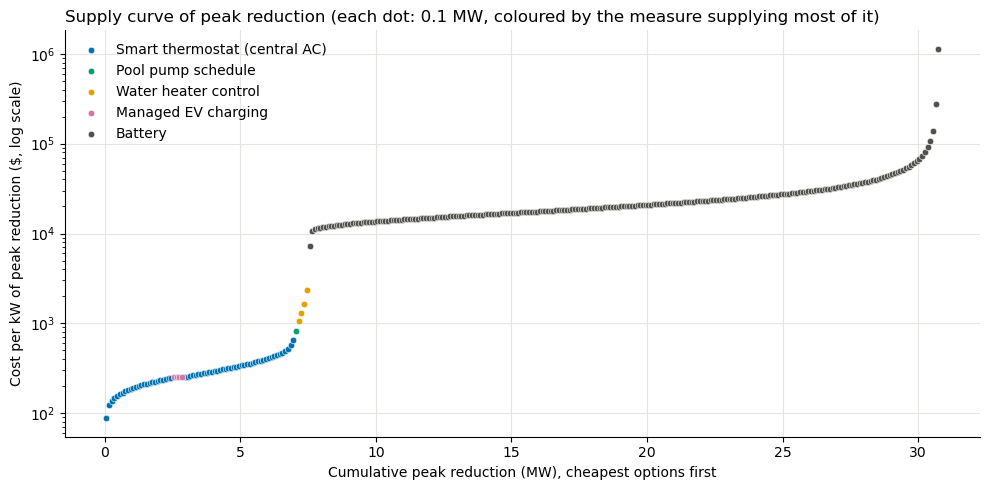

┌───────────────────────────────┬───────┬──────────┬─────────────┬───────────┬─────────────┬─────────────────────────┬──────────────────┐
│ option                        ┆ homes ┆ total_mw ┆ kw_per_home ┆ cost_musd ┆ cost_per_kw ┆ median_home_cost_per_kw ┆ cost_per_kw_year │
│ ---                           ┆ ---   ┆ ---      ┆ ---         ┆ ---       ┆ ---         ┆ ---                     ┆ ---              │
│ str                           ┆ u32   ┆ f64      ┆ f64         ┆ f64       ┆ f64         ┆ f64                     ┆ f64              │
╞═══════════════════════════════╪═══════╪══════════╪═════════════╪═══════════╪═════════════╪═════════════════════════╪══════════════════╡
│ Managed EV charging           ┆ 479   ┆ 0.38     ┆ 0.78        ┆ 0.10      ┆ 254.96      ┆ 250.00                  ┆ 25.50            │
│ Smart thermostat (central AC) ┆ 12028 ┆ 6.19     ┆ 0.51        ┆ 1.80      ┆ 291.36      ┆ 313.77                  ┆ 29.14            │
│ Pool pump schedule            ┆ 

In [6]:
batt_kw = np.nan_to_num(bat['grid_peak_kw_reduction'].to_numpy())


def build_stack(flex_by_measure):
    """Every option ranked by cost per kW; a battery is credited with what it adds to that home's flexible loads."""
    added = np.maximum(batt_kw - ON_SHARE * np.sum(list(flex_by_measure.values()), axis=0), 0)
    parts = [pl.DataFrame({'i': np.flatnonzero(v > 0.01), 'option': k, 'kw': v[v > 0.01], 'cost': float(COST[k])})
             for k, v in flex_by_measure.items()]
    parts.append(pl.DataFrame({'i': np.flatnonzero(added > 0.01), 'option': 'Battery', 'kw': added[added > 0.01],
                               'cost': float(COST['Battery'])}))
    ranked = (pl.concat(parts).with_columns((pl.col('cost') / pl.col('kw')).alias('cost_per_kw')).sort('cost_per_kw')
              .with_columns((pl.col('kw').cum_sum() / 1000).alias('cum_mw'),
                            (pl.col('cost').cum_sum() / 1e6).alias('cum_cost_musd')))
    return ranked, added


stack, batt_incr = build_stack(flex)
print(f'Battery: average cut {batt_kw.mean():.2f} kW per home ({batt_kw.sum() / peak_kw.sum():.0%} of the peak-hour load), '
      f'{batt_kw.sum() / 1000:.1f} MW if every home had one, ${COST["Battery"] * n / 1e6:,.0f}M')
print(f'Added on top of the flexible loads: {batt_incr.sum() / 1000:.1f} MW')

only = (pl.DataFrame({'kw': batt_kw[batt_kw > 0.01]}).with_columns((COST['Battery'] / pl.col('kw')).alias('cost_per_kw'))
        .sort('cost_per_kw').with_columns((pl.col('kw').cum_sum() / 1000).alias('cum_mw'))
        .with_row_index('homes', offset=1).with_columns((pl.col('homes') * COST['Battery'] / 1e6).alias('cum_cost_musd')))

STEP_MW = 0.1
steps = (stack.with_columns((pl.col('cum_mw') / STEP_MW).floor().alias('step'))
         .group_by('step', 'option').agg(pl.col('kw').sum(), pl.col('cost').sum())
         .with_columns(pl.col('kw').sum().over('step').alias('step_kw'), pl.col('cost').sum().over('step').alias('step_cost'))
         .sort('step', 'kw', descending=[False, True]).group_by('step', maintain_order=True).first()
         .with_columns((pl.col('step_cost') / pl.col('step_kw')).alias('cost_per_kw'), ((pl.col('step') + 0.5) * STEP_MW).alias('mw')))
fig, ax = plt.subplots(figsize=(10, 5))
for k, color in COLORS.items():
    d = steps.filter(pl.col('option') == k)
    ax.scatter(d['mw'], d['cost_per_kw'], s=22, color=color, label=k, edgecolor='white', linewidth=0.4)
ax.set_yscale('log')
ax.set_xlabel('Cumulative peak reduction (MW), cheapest options first')
ax.set_ylabel('Cost per kW of peak reduction ($, log scale)')
ax.set_title('Supply curve of peak reduction (each dot: 0.1 MW, coloured by the measure supplying most of it)', loc='left')
ax.legend(frameon=False, loc='upper left')
ax.grid(color='#e6e5e1')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(PLOT_DIR / 'peak_reduction_supply_curve.png', dpi=150)
plt.show()

summary = (stack.group_by('option', maintain_order=True).agg(
    pl.len().alias('homes'), (pl.col('kw').sum() / 1000).alias('total_mw'), pl.col('kw').mean().alias('kw_per_home'),
    (pl.col('cost').sum() / 1e6).alias('cost_musd'), (pl.col('cost').sum() / pl.col('kw').sum()).alias('cost_per_kw'),
    pl.col('cost_per_kw').median().alias('median_home_cost_per_kw'))
    .with_columns((pl.col('cost_per_kw') / pl.col('option').replace_strict(LIFE_YEARS, return_dtype=pl.Float64))
                  .alias('cost_per_kw_year')).sort('cost_per_kw'))
cache.save_results('peak_reduction_options', summary)
with pl.Config(tbl_hide_dataframe_shape=True, float_precision=2, fmt_str_lengths=40, tbl_width_chars=180):
    print(summary)

### Cost of reaching a target

For a range of targets, the cost of the cheapest options from the full stack against **batteries alone** (the best
battery homes first). In the 25% enrolment case a random quarter of the flagged homes take up each flexible-load measure, and
batteries fill the rest.

┌───────────┬──────────────────────┬─────────────────┬────────────────────┬────────────────────────────┬─────────────────────┬──────────────────────┬─────────────────────────┐
│ target_mw ┆ share_of_system_peak ┆ stack_cost_musd ┆ batteries_in_stack ┆ stack_25pct_enrolment_musd ┆ batteries_only_musd ┆ batteries_only_homes ┆ batteries_only_vs_stack │
│ ---       ┆ ---                  ┆ ---             ┆ ---                ┆ ---                        ┆ ---                 ┆ ---                  ┆ ---                     │
│ i64       ┆ f64                  ┆ f64             ┆ i64                ┆ f64                        ┆ f64                 ┆ i64                  ┆ f64                     │
╞═══════════╪══════════════════════╪═════════════════╪════════════════════╪════════════════════════════╪═════════════════════╪══════════════════════╪═════════════════════════╡
│ 1         ┆ 0.01                 ┆ 0.15            ┆ 0                  ┆ 0.22                       ┆ 9.47           

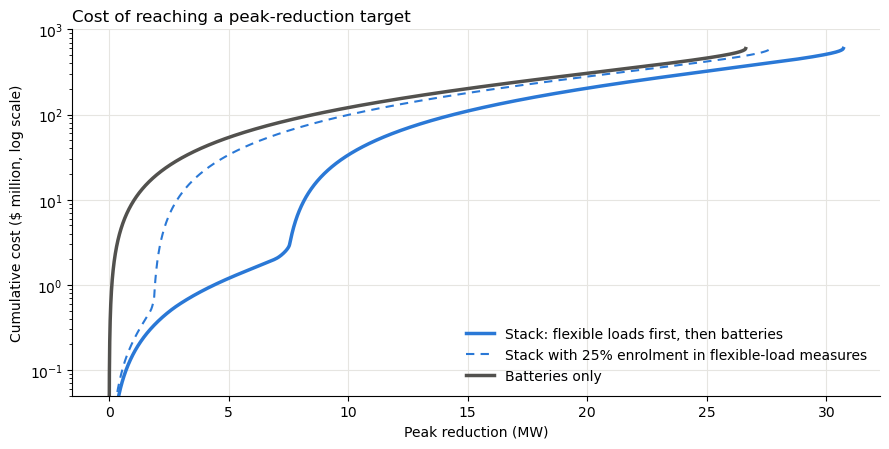

In [7]:
def cost_to(df, mw):
    d = df.filter(pl.col('cum_mw') >= mw)
    return float(d['cum_cost_musd'][0]) if d.height else None


rng = np.random.default_rng(0)
enrolled, _ = build_stack({k: np.where(rng.random(n) < ENROLMENT_CASE, v, 0.0) for k, v in flex.items()})
rows = []
for mw in [1, 2, 5, 10, 15, 20, 25]:
    used = stack.filter(pl.col('cum_mw') <= max(mw, float(stack['cum_mw'][0])))
    rows.append({'target_mw': mw, 'share_of_system_peak': mw * 1000 / system.max(),
                 'stack_cost_musd': cost_to(stack, mw), 'batteries_in_stack': int((used['option'] == 'Battery').sum()),
                 'stack_25pct_enrolment_musd': cost_to(enrolled, mw), 'batteries_only_musd': cost_to(only, mw),
                 'batteries_only_homes': int(only.filter(pl.col('cum_mw') <= mw).height)})
targets = pl.DataFrame(rows).with_columns((pl.col('batteries_only_musd') / pl.col('stack_cost_musd')).alias('batteries_only_vs_stack'))
cache.save_results('peak_reduction_targets', targets)
with pl.Config(tbl_hide_dataframe_shape=True, float_precision=2, tbl_width_chars=200):
    print(targets)

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(stack['cum_mw'], stack['cum_cost_musd'], color='#2a78d6', linewidth=2.5, label='Stack: flexible loads first, then batteries')
ax.plot(enrolled['cum_mw'], enrolled['cum_cost_musd'], color='#2a78d6', linewidth=1.5, linestyle=(0, (4, 3)),
        label=f'Stack with {ENROLMENT_CASE:.0%} enrolment in flexible-load measures')
ax.plot(only['cum_mw'], only['cum_cost_musd'], color='#52514e', linewidth=2.5, label='Batteries only')
ax.set_yscale('log')
ax.set_ylim(0.05, 1000)
ax.set_xlabel('Peak reduction (MW)')
ax.set_ylabel('Cumulative cost ($ million, log scale)')
ax.set_title('Cost of reaching a peak-reduction target', loc='left')
ax.legend(frameon=False, loc='lower right')
ax.grid(color='#e6e5e1')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(PLOT_DIR / 'peak_reduction_cost_to_target.png', dpi=150)
plt.show()

### Would batteries do better if dispatched for the grid's peak, not the tariff's?

In notebook 80 each battery discharges in the tariff's on-peak window, which covers under half of the grid's 100
highest hours (section 1). As an **upper bound** on what the same battery could do if the utility dispatched it in
those 100 hours instead: on each peak day, the battery serves the home's load in that day's peak hours, up to its
power rating in any hour and its usable energy over the day, and is assumed to recharge fully before the next peak
day. This isn't a dispatch simulation (it assumes the peak hours are known in advance and ignores the charging
plan), so the real figure lies between notebook 80's and this one.

In [8]:
B = bt.Battery()
usable = B.capacity_kwh * (1 - B.reserve_fraction) * np.sqrt(B.round_trip_efficiency)
grid_kw = np.zeros(n)
for d in np.unique(top_day):
    served = np.minimum(L[:, d, top_hour[top_day == d]], B.power_kw).sum(1, dtype=np.float64)
    grid_kw += np.minimum(served, usable)
grid_kw /= PEAK_HOURS
order = np.argsort(-grid_kw)[:n // 10]
print(f'Usable energy per day: {usable:.1f} kWh; longest peak day: {np.bincount(top_day).max()} of the 100 hours.')
print(f'Tariff dispatch (notebook 80): {batt_kw.mean():.2f} kW per home, {batt_kw.sum() / 1000:.1f} MW, '
      f'${COST["Battery"] * n / batt_kw.sum():,.0f} per kW')
print(f'Grid-peak dispatch (upper bound): {grid_kw.mean():.2f} kW per home, {grid_kw.sum() / 1000:.1f} MW '
      f'({grid_kw.sum() / peak_kw.sum():.0%} of the peak-hour load), ${COST["Battery"] * n / grid_kw.sum():,.0f} per kW')
print(f'Best 10% of homes under grid-peak dispatch: {grid_kw[order].mean():.2f} kW each, {grid_kw[order].sum() / 1000:.1f} MW, '
      f'${COST["Battery"] * len(order) / grid_kw[order].sum():,.0f} per kW, '
      f'${COST["Battery"] / LIFE_YEARS["Battery"] * len(order) / grid_kw[order].sum():,.0f} per kW-year')

Usable energy per day: 19.1 kWh; longest peak day: 13 of the 100 hours.
Tariff dispatch (notebook 80): 0.80 kW per home, 26.6 MW, $22,525 per kW
Grid-peak dispatch (upper bound): 1.54 kW per home, 51.2 MW (81% of the peak-hour load), $11,700 per kW
Best 10% of homes under grid-peak dispatch: 2.76 kW each, 9.2 MW, $6,515 per kW, $434 per kW-year


## 5. Which homes should get batteries

Batteries differ enormously in what they deliver: the cost is the same in every home, but the peak reduction isn't.
The tables rank clusters by battery cost per kW of **added** peak reduction (after the flexible loads), with the
average bill savings from notebook 80 (placeholder tariff) and the share of each cluster's homes in the best 10% of
all battery homes. First by notebook 75's clusters, then by notebook 70's segments.

In [9]:
home = pl.DataFrame({'CUSTOMER_NUMBER': hd.customer_numbers, 'cluster': cluster, 'segment_70': seg70, 'peak_kw': peak_kw,
                     'flex_kw': flex_kw, 'battery_kw': batt_kw, 'battery_added_kw': batt_incr,
                     'bill_savings': np.nan_to_num(bat['bill_savings'].to_numpy())})
home = home.with_columns((COST['Battery'] / pl.col('battery_added_kw').clip(lower_bound=1e-3)).alias('battery_cost_per_kw'))
home = home.with_columns(pl.col('battery_cost_per_kw').rank('ordinal').alias('battery_rank'))
best = home['battery_rank'] <= n // 10


def by(col):
    return (home.with_columns(best.alias('best')).group_by(col).agg(
        pl.len().alias('homes'), pl.col('peak_kw').mean().alias('avg_peak_kw'), pl.col('flex_kw').mean().alias('avg_flex_kw'),
        pl.col('battery_added_kw').mean().alias('avg_battery_added_kw'),
        (COST['Battery'] * pl.len() / pl.col('battery_added_kw').sum()).alias('battery_cost_per_kw'),
        pl.col('bill_savings').mean().alias('avg_bill_savings'), pl.col('best').mean().alias('share_in_best_10pct'))
        .with_columns((COST['Battery'] / pl.col('avg_bill_savings')).alias('payback_years')).sort('battery_cost_per_kw'))


rank_cluster, rank_segment = by('cluster'), by('segment_70')
cache.save_results('peak_reduction_battery_by_cluster', rank_cluster)
with pl.Config(tbl_rows=-1, tbl_hide_dataframe_shape=True, float_precision=2, fmt_str_lengths=70, tbl_width_chars=220):
    print(rank_cluster)
    print(rank_segment)

top10 = home.filter(best)
print(f'Best 10% of battery homes ({top10.height:,}): {top10["battery_added_kw"].mean():.2f} kW added each, '
      f'{top10["battery_added_kw"].sum() / 1000:.1f} MW in total for ${COST["Battery"] * top10.height / 1e6:,.0f}M '
      f'(${COST["Battery"] * top10.height / top10["battery_added_kw"].sum():,.0f} per kW); '
      f'average bill savings ${top10["bill_savings"].mean():,.0f} a year.')

┌────────────────────────────────────────────────────────────────┬───────┬─────────────┬─────────────┬───┬─────────────────────┬──────────────────┬─────────────────────┬───────────────┐
│ cluster                                                        ┆ homes ┆ avg_peak_kw ┆ avg_flex_kw ┆ … ┆ battery_cost_per_kw ┆ avg_bill_savings ┆ share_in_best_10pct ┆ payback_years │
│ ---                                                            ┆ ---   ┆ ---         ┆ ---         ┆   ┆ ---                 ┆ ---              ┆ ---                 ┆ ---           │
│ str                                                            ┆ u32   ┆ f64         ┆ f64         ┆   ┆ f64                 ┆ f64              ┆ f64                 ┆ f64           │
╞════════════════════════════════════════════════════════════════╪═══════╪═════════════╪═════════════╪═══╪═════════════════════╪══════════════════╪═════════════════════╪═══════════════╡
│ 1: central AC 99%, heavy cooling                               ┆ 102

Best 10% of battery homes (3,331): 1.35 kW added each, 4.5 MW in total for $60M ($13,297 per kW); average bill savings $581 a year.


## 6. Who pays?

Two separate questions:

- **Does a battery pay for itself from the customer's bill savings?** Simple payback = battery cost ÷ annual bill
  savings (notebook 80, placeholder tariff). Those bill savings are the utility's lost revenue, not new revenue.
- **What would the peak reduction have to be worth to the utility?** The **break-even capacity value** is each
  option's annualized cost per kW of peak reduction: if avoiding a kW of peak capacity (generation, transmission and
  distribution) is worth more than this per year, the option pays for itself on capacity alone.

In [10]:
payback = COST['Battery'] / np.maximum(home['bill_savings'].to_numpy(), 1e-9)
print('Battery simple payback from bill savings (years): '
      + ', '.join(f'{name} {np.quantile(payback, q):.0f}' for name, q in [('best 1%', 0.01), ('best 10%', 0.10), ('median', 0.5)]))
print(f'Homes paying back within the {LIFE_YEARS["Battery"]}-year battery life: {(payback <= LIFE_YEARS["Battery"]).mean():.1%}')
print(f'Battery cost at which the median home breaks even over {LIFE_YEARS["Battery"]} years: '
      f'${np.median(home["bill_savings"]) * LIFE_YEARS["Battery"]:,.0f}; the best 10% of homes by savings: '
      f'${np.quantile(home["bill_savings"], 0.9) * LIFE_YEARS["Battery"]:,.0f}')

rows = [{'option': r['option'], 'break_even_capacity_value_per_kw_year': r['cost_per_kw_year']}
        for r in summary.filter(pl.col('option') != 'Battery').iter_rows(named=True)]
for label, sel in [('Battery, best 10% of homes', best.to_numpy()), ('Battery, all homes', np.ones(n, bool))]:
    kw = home['battery_added_kw'].to_numpy()[sel].sum()
    rows.append({'option': label,
                 'break_even_capacity_value_per_kw_year': COST['Battery'] / LIFE_YEARS['Battery'] * sel.sum() / kw})
    net = (COST['Battery'] / LIFE_YEARS['Battery'] - home['bill_savings'].to_numpy()[sel]).sum() / kw
    rows.append({'option': label + ', net of bill savings', 'break_even_capacity_value_per_kw_year': net})
break_even = pl.DataFrame(rows)
cache.save_results('peak_reduction_break_even', break_even)
with pl.Config(tbl_hide_dataframe_shape=True, float_precision=0, fmt_str_lengths=60):
    print(break_even)

Battery simple payback from bill savings (years): best 1% 22, best 10% 27, median 45
Homes paying back within the 15-year battery life: 0.0%
Battery cost at which the median home breaks even over 15 years: $5,991; the best 10% of homes by savings: $9,832
┌─────────────────────────────────────────────────┬───────────────────────────────────────┐
│ option                                          ┆ break_even_capacity_value_per_kw_year │
│ ---                                             ┆ ---                                   │
│ str                                             ┆ f64                                   │
╞═════════════════════════════════════════════════╪═══════════════════════════════════════╡
│ Managed EV charging                             ┆ 25                                    │
│ Smart thermostat (central AC)                   ┆ 29                                    │
│ Pool pump schedule                              ┆ 46                                    │
│ Water h

## 7. Save

`peak_reduction_stack` (one row per customer in the analysis): cluster, load in the peak hours, the peak reduction
from each flexible-load measure, the battery's simulated and added reduction (and the grid-dispatch upper bound), its cost per kW and
rank, and the bill savings.

In [11]:
out = home.with_columns(
    *[pl.Series(name, v) for name, v in zip(['thermostat_kw', 'pool_pump_kw', 'water_heater_kw', 'ev_charging_kw'], flex.values())],
    pl.Series('battery_kw_grid_dispatch_bound', grid_kw),
    (COST['Battery'] / pl.col('bill_savings').clip(lower_bound=1e-9)).alias('battery_payback_years'),
).select('CUSTOMER_NUMBER', 'cluster', 'segment_70', 'peak_kw', 'thermostat_kw', 'pool_pump_kw', 'water_heater_kw',
         'ev_charging_kw', 'flex_kw', 'battery_kw', 'battery_added_kw', 'battery_kw_grid_dispatch_bound', 'battery_cost_per_kw', 'battery_rank',
         'bill_savings', 'battery_payback_years')
with db.connect(read_only=False) as con:
    con.register('stack_df', out)
    con.execute('CREATE OR REPLACE TABLE peak_reduction_stack AS SELECT * FROM stack_df ORDER BY battery_rank')
out.sort('battery_rank').write_csv(PLOT_DIR / 'peak_reduction_stack.csv')
print(f'peak_reduction_stack: {out.height:,} customers')

peak_reduction_stack: 33,310 customers


## What this shows

*Figures from the 13 Nov 2026 run (33,310 customers) with the placeholder costs in section 2; the tables above
update on a re-run, this text doesn't.*

**The peak is narrow and one cluster drives it.** The grid's 100 highest hours fall on 18 summer days. The central-AC
cluster is 31% of customers and 47% of the load in those hours (2.9 kW per home against 1.0 kW in the no-AC cluster).

**Flexible loads are by far the cheapest peak reduction.** The four measures together take an estimated **7.6 MW**
off the peak hours (12% of the load in those hours) from 14,361 homes for about **$3 million**:

| Measure | Homes | Peak reduction | Cost per kW |
|---|---|---|---|
| Smart-thermostat events, central AC | 12,028 | 6.2 MW | $290 |
| Managed EV charging (assumed, not measured) | 479 | 0.4 MW | $255 |
| Pool pump schedules | 1,187 | 0.5 MW | $460 |
| Water heater control | 3,028 | 0.5 MW | $1,960 |
| Battery (added on top of the above) | 32,970 | 23.2 MW | $25,600 |

Thermostats in the central-AC cluster are almost the whole of it. Water heaters contribute little at peak: their
evening draws are small and only partly overlap the peak hours.

**Batteries cost 50–100 times as much per kW as thermostats, EV charging and pool pumps.** A battery cuts the average home's load in the peak hours by only
0.8 kW, because homes draw about 1.9 kW in those hours and the battery follows the tariff, not the grid.
Reaching 5 MW costs about $1.2 million with the stack and $54 million with batteries alone (2,990 of them). Beyond the
7.6 MW of flexible load, batteries are the only option here, so 10 MW costs $34 million with the stack and $121
million without it. If only a quarter of flagged homes enrol in the flexible-load measures, 5 MW costs $34 million,
so enrolment is worth far more than battery targeting.

**The tariff's on-peak window misses half the peak.** Only 46% of the 100 highest hours are inside 4–9 pm on
weekdays: 30% are earlier in the afternoon, 8% later, and 20% fall on weekends. If the same batteries were dispatched
for the grid's peak hours instead, the upper bound is 1.5 kW per home (51 MW, $11,700 per kW), roughly twice the
tariff-dispatched figure, and 2.8 kW per home ($6,500 per kW) in the best 10% of homes.

**Which homes for batteries.** The best 10% of battery homes (3,331) add 1.35 kW each: 4.5 MW for $60 million. They
are concentrated in the central-AC cluster (20% of its homes are in the best 10%, against 1–3% in the no-AC, solar
and primary-electric-heat clusters) and, in notebook 70's terms, among evening peakers (23%) and large, steady homes
(15%).

**No battery pays for itself from bill savings at these costs.** Under the placeholder tariff, simple payback is 22
years for the best 1% of homes, 27 for the best 10% and 45 for the median, against a 15-year life. The median home
breaks even only if the installed battery costs about $6,000; the best 10% of homes by savings at about $9,800. And
those bill savings are revenue the utility loses, not revenue it gains.

**What the peak reduction would need to be worth.** Break-even capacity value, per kW of peak reduction per year:
about $25–46 for EV charging, thermostats and pool pumps, $196 for water heaters, and **$886 for the best 10% of
battery homes** ($457 net of the customer's bill savings; $1,726 for all homes). Batteries make sense for the utility
only where avoided capacity is worth more than that, or where they deliver other value not counted here (backup
power, local feeder relief, wholesale arbitrage).

**Limits.**
- "Peak reduction" is the cut in average load over the 100 highest hours, not headroom on the single system peak.
  The 100th-highest hour is 57 MW against a 78 MW peak, so cutting those hours by more than about 21 MW would only
  move the peak to other hours.
- Thermostat events are assumed to shed 30% of cooling load in all 100 hours (up to 13 hours on one day), with no
  rebound afterwards. Real events are shorter, so 6.2 MW is an upper estimate.
- Costs, the tariff and the EV figure are placeholders. The flags are unvalidated; notebook 95 shows the water-heater
  flag is partly confused with hot tubs.

## Tried but not used

| Tried | Why it isn't used |
|---|---|
| **Crediting each battery with its full simulated cut**, alongside the flexible loads in the same home | Double-counts: in the tariff's on-peak hours the battery already serves nearly all of the home's load, so a thermostat event there only displaces battery discharge. Batteries are credited with what they add (30.7 MW for the full stack, not 34.2 MW). |
| **Hot tubs as a flexible load** | Left out: notebook 95 shows the hot-tub and water-heater rules trip each other in 29–77% of homes, so counting both would count the same load twice. |
| **Thermostat events for room-AC homes** | Left out: window and room units aren't controlled by a central thermostat. They are 39% of homes, so a plug-level control programme would be a separate measure. |
| **A dispatch simulation of batteries on the grid's peak hours** | Only an upper bound is computed (section 4). A proper simulation needs a rule for calling events from a forecast, and a charging plan that doesn't create a new peak, as notebook 80's coordinated windows do. |
| **Load rebound after thermostat events, and shorter events** | Not modelled; the thermostat figure is an upper estimate (see Limits). |